# Can surface history improve ATP match predictions beyond ranking?

**Data foundations · 2015–2025 ATP men's singles**

The training figures and 2023 ranking benchmark below lead into a worked example from the Cincinnati final. Sections 3–5 define the two planned models, final evaluation and literature comparison. To reproduce the results, fetch the pinned seasons as described in the repository README and run the notebook from its root.

## 1. Predictive task

At the start of a tournament, predict which of two players would win a given singles match, conditional on both playing and completing it. The inputs must already be observable at that time. The prediction target is whether player A wins. The data preparation code assigns the lexicographically smaller player ID to A before constructing features. Each match has one A/B orientation.

The comparison of interest is between two probability models. Both receive the players' rankings. One also receives each player's prior record on the surface of the upcoming match. A simple reference rule always picks the player with the better ranking (the smaller number).

## 2. Exploratory analysis, data collection and preprocessing

TennisMyLife distributes annual ATP match files with tournament start weeks, surfaces, player identities, rankings and results. The project covers main-draw singles at Grand Slams, Masters and tour-level events on hard, clay or grass courts. The shared loader in `scripts/baseline.py` checks identity, rankings and score eligibility and reports the first reason for each exclusion. Season counts below describe coverage. Only the training seasons contribute outcomes to the first figure. [Dataset and field descriptions](https://stats.tennismylife.org/tennis-match-database)

In [1]:
from bisect import bisect_left
from collections import Counter
from datetime import timedelta
from math import isclose, log

import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

from scripts.baseline import load_matches, ranking_result, split_name
from scripts.prepare_data import build_model_rows

matches, audit = load_matches()
train = [match for match in matches if split_name(match["season"]) == "train"]
validation = [match for match in matches if split_name(match["season"]) == "validation"]
split_counts = Counter(split_name(match["season"]) for match in matches)

print("Eligible matches by season group")
for group, seasons in (("warmup", "2015"), ("train", "2016–2022"),
                       ("validation", "2023"), ("test", "2024–2025")):
    print(f"  {seasons:10} {group:12} {split_counts[group]:>7,}")

totals = Counter()
for season_counts in audit.values():
    totals.update(season_counts)
print(f"\nCleaning audit across all files: {totals['raw']:,} rows read")
for key, label in (("level", "Event level"), ("surface", "Surface"),
                   ("player_id", "Player identity"), ("ranking", "Ranking"),
                   ("score", "Score"), ("duplicate", "Duplicate draw row"),
                   ("spurious", "Spurious draw row")):
    print(f"  Excluded · {label:16} {totals[key]:>7,}")
print(f"  Eligible                    {totals['eligible']:>7,}")

Eligible matches by season group
  2015       warmup         2,507
  2016–2022  train         16,186
  2023       validation     2,588
  2024–2025  test           5,088

Cleaning audit across all files: 30,716 rows read
  Excluded · Event level        3,303
  Excluded · Surface                0
  Excluded · Player identity        0
  Excluded · Ranking               70
  Excluded · Score                971
  Excluded · Duplicate draw row       2
  Excluded · Spurious draw row       1
  Eligible                     26,369


### How often does the better-ranked player win?

Group training matches by the absolute difference between the opponents' rankings. The dashed line marks a 50% win rate. Labels give the win rate and the number of matches in each bin. Equal rankings have no favorite under this rule.

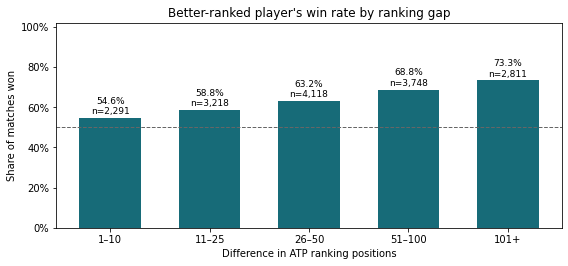

In [2]:
gap_limits = [10, 25, 50, 100]
gap_labels = ["1–10", "11–25", "26–50", "51–100", "101+"]
gap_groups = [[] for label in gap_labels]
for match in train:
    gap = abs(match["winner_rank"] - match["loser_rank"])
    if gap > 0:
        gap_groups[bisect_left(gap_limits, gap)].append(match)

gap_results = [ranking_result(group) for group in gap_groups]
win_rates = [correct / count for correct, count in gap_results]

fig, ax = plt.subplots(figsize=(8, 3.8))
bars = ax.bar(gap_labels, win_rates, color="#176B78", width=0.62)
ax.axhline(0.5, color="#666666", linewidth=1, linestyle="--")
for bar, rate, (_, count) in zip(bars, win_rates, gap_results):
    ax.text(bar.get_x() + bar.get_width() / 2, rate + 0.02,
            f"{rate:.1%}\nn={count:,}", ha="center", fontsize=9)
ax.set(title="Better-ranked player's win rate by ranking gap",
       xlabel="Difference in ATP ranking positions", ylabel="Share of matches won",
       ylim=(0, 1.02))
ax.yaxis.set_major_formatter(PercentFormatter(1))
fig.tight_layout()
plt.show()

For a gap of 1–10 places, the favorite won 54.6% of training matches. For a gap of 101 or more places, the rate was 73.3%. Ranking therefore supplies a meaningful starting point, especially when the players are far apart.

### How much same-surface history is available before a tournament?

Count eligible prior matches for each player appearing in each training match. History can draw on the 2015 warm-up season and earlier training matches. For a tournament starting on date $d$, count starts from $d-364$ through $d-21$ days, inclusive. The three-week buffer handles the fact that every round in an event shares its start week.

Each player appearance contributes once, so a player competing in several matches contributes several observations. Percentages are calculated within each surface.

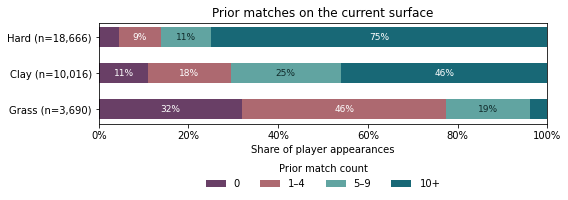

Hard: 2,580 of 18,666 appearances had fewer than five prior matches (13.8%).
Clay: 2,942 of 10,016 appearances had fewer than five prior matches (29.4%).
Grass: 2,859 of 3,690 appearances had fewer than five prior matches (77.5%).


In [3]:
model_rows = build_model_rows(matches)
surfaces = ["Hard", "Clay", "Grass"]
coverage_labels = ["0", "1–4", "5–9", "10+"]
coverage = {surface: Counter() for surface in surfaces}
for row in model_rows:
    if row["split"] == "train":
        for history_count in (row["surface_matches_a"], row["surface_matches_b"]):
            bucket = bisect_left([0, 4, 9], history_count)
            coverage[row["surface"]][bucket] += 1

counts = [sum(coverage[surface].values()) for surface in surfaces]
assert sum(counts) == 2 * len(train)
colors = ["#693F66", "#AD6970", "#61A4A1", "#186876"]
fig, ax = plt.subplots(figsize=(8, 3.2))
left = [0.0] * len(surfaces)
for bucket, (label, color) in enumerate(zip(coverage_labels, colors)):
    shares = [coverage[surface][bucket] / n for surface, n in zip(surfaces, counts)]
    ax.barh(surfaces, shares, left=left, height=0.55, label=label, color=color)
    for i, share in enumerate(shares):
        if share >= 0.08:
            ax.text(left[i] + share / 2, i, f"{share:.0%}", ha="center",
                    va="center", color="white" if bucket != 2 else "#102B2B", fontsize=9)
    left = [a + b for a, b in zip(left, shares)]
ax.set_yticks(range(len(surfaces)))
ax.set_yticklabels([f"{s} (n={n:,})" for s, n in zip(surfaces, counts)])
ax.invert_yaxis()
ax.set(title="Prior matches on the current surface", xlabel="Share of player appearances",
       xlim=(0, 1))
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.legend(title="Prior match count", ncol=4, loc="upper center",
          bbox_to_anchor=(0.5, -0.31), frameon=False)
fig.tight_layout()
plt.show()

for surface, n in zip(surfaces, counts):
    sparse = coverage[surface][0] + coverage[surface][1]
    print(f"{surface}: {sparse:,} of {n:,} appearances had fewer than five prior matches ({sparse/n:.1%}).")

Grass has the sparsest history: 77.5% of training appearances have fewer than five eligible prior grass matches under this window. The corresponding shares are 29.4% on clay and 13.8% on hard courts. This motivates shrinking small-sample win rates toward 0.5 before comparing the models.

### Data foundations and one verified match

The prepared table has one row per training or validation **match**. Each player's intermediate count measures prior **matches on the current surface**. The CLI writes the same rows to `data/processed/model_input.csv`. Player IDs, names, split and dates identify the observation. The two candidate numerical inputs are `log_rank_diff = log(rank_B) − log(rank_A)` and `surface_rate_diff = rate_A − rate_B`. Positive values favor A. The observed label `a_won` is stored separately from these inputs. See the [published feature CSV](data/processed/model_input.csv), [processing guide](docs/data-processing.md), [column definitions](DATA.md) and [outcome rules](OUTCOMES.md) for details.

In [4]:
prepared_counts = Counter(row["split"] for row in model_rows)
assert prepared_counts == {"train": len(train), "validation": len(validation)}
assert len({row["match_id"] for row in model_rows}) == len(model_rows)
print(f"{len(model_rows):,} unique matches · "
      f"{prepared_counts['train']:,} training + {prepared_counts['validation']:,} validation")

18,774 unique matches · 16,186 training + 2,588 validation


**Cincinnati final, 2023 · Carlos Alcaraz vs. Novak Djokovic.** Replay one validation observation directly from the cleaned source matches. The reference scan below rebuilds each player's eligible hard-court history and checks the stored counts, wins, smoothed rate and latest contributing tournament week. The players are identified by ID. The dates refer to tournament starts, including the start used as this prediction's cutoff.

In [5]:
example = next(row for row in model_rows if row["match_id"] == "2023-422:55")
source = next(m for m in validation
              if (m["tourney_id"], m["match_num"]) == (example["tourney_id"], example["match_num"]))
expected_ids = sorted([source["winner_id"], source["loser_id"]])
assert expected_ids == [example["player_a_id"], example["player_b_id"]]

start = source["tourney_date"]
window_start, window_end = start - timedelta(weeks=52), start - timedelta(days=21)
print(f"{example['surface']} court · tournament starts {start}")
print(f"Eligible prior tournament starts: {window_start} through {window_end} (inclusive)")

for side in ("a", "b"):
    player_id = example[f"player_{side}_id"]
    history = [m for m in matches
               if m["surface"] == source["surface"]
               and window_start <= m["tourney_date"] <= window_end
               and player_id in (m["winner_id"], m["loser_id"])]
    wins = sum(m["winner_id"] == player_id for m in history)
    count = len(history)
    rate = (wins + 1) / (count + 2)
    latest = max(m["tourney_date"] for m in history).isoformat()

    assert (count, wins, latest) == (example[f"surface_matches_{side}"],
                                     example[f"surface_wins_{side}"],
                                     example[f"latest_history_date_{side}"])
    assert isclose(rate, example[f"surface_rate_{side}"])
    name = example[f"player_{side}_name"]
    rank = example[f"rank_{side}"]
    print(f"{side.upper()}  {name} ({player_id}), rank {rank}: {wins}/{count} wins, "
          f"smoothed {(wins + 1)}/{(count + 2)} = {rate:.1%}, latest start {latest}")

assert isclose(log(example["rank_b"]) - log(example["rank_a"]), example["log_rank_diff"])
assert isclose(example["surface_rate_a"] - example["surface_rate_b"], example["surface_rate_diff"])
print(f"Inputs: log-rank difference {example['log_rank_diff']:+.3f}, "
      f"surface-rate difference {100 * example['surface_rate_diff']:+.1f} percentage points")

Hard court · tournament starts 2023-08-14
Eligible prior tournament starts: 2022-08-15 through 2023-07-24 (inclusive)
A  Carlos Alcaraz (A0E2), rank 1: 22/26 wins, smoothed 23/28 = 82.1%, latest start 2023-03-20
B  Novak Djokovic (D643), rank 2: 27/29 wins, smoothed 28/31 = 90.3%, latest start 2023-02-27
Inputs: log-rank difference +0.693, surface-rate difference -8.2 percentage points


In [6]:
# Reveal the recorded target only after checking the pre-tournament inputs.
assert example["a_won"] == int(source["winner_id"] == example["player_a_id"])
print(f"Observed outcome: {source['winner_name']} won. Target a_won = {example['a_won']}.")

Observed outcome: Novak Djokovic won. Target a_won = 0.


Alcaraz had the better ranking. Djokovic had the higher historical hard-court win rate under the chosen window. The model comparison will measure how often that additional information helps across matches.

## 3. Modeling

**Implemented reference.** The ranking rule picks the player with the smaller ranking number whenever the ranks differ. It has no fitted parameters.

**Next experiment.** Fit two regularized logistic regressions on the 2016–2022 matches. Give both models `log_rank_diff` and give the second model `surface_rate_diff` as well. Both estimate the probability that A wins. Use 2023 to select settings and hold the scored matches fixed across comparisons. The historical rates treat every prior opponent equally, so an easy schedule could make a player look stronger on a surface.

The verified table and worked example above supply the features. The next contributor fits the models, checks validation predictions and records the settings for final evaluation.

## 4. Evaluation

First measure the always-pick-the-better-ranking rule on validation matches. Ties in ranking have no rule-based pick and are excluded from the denominator. Apply the same eligibility rule for model comparisons.

In [7]:
correct, scored = ranking_result(validation)
print("2023 validation · pick the better-ranked player")
print(f"Correct picks: {correct:,} / {scored:,} ({correct / scored:.2%})")
print(f"Equal-ranking matches without a pick: {len(validation) - scored:,}")

2023 validation · pick the better-ranked player
Correct picks: 1,640 / 2,588 (63.37%)
Equal-ranking matches without a pick: 0


**How to read the metrics.** Accuracy counts correct winner picks. Log loss also measures confidence. For example, if A wins, assigning A a hypothetical 0.80 chance incurs a loss of $-\log(0.8)\approx0.223$, while assigning A a 0.20 chance incurs about 1.609. Lower average log loss is better.

**Pending final evaluation.** Score the frozen models on exactly the same eligible matches from 2024 and 2025. Report sample counts, accuracy and changes in percentage points, plus log loss for each probability model. Compare the two test seasons separately and combined. Use the full test set to support the conclusion and one match to illustrate it.

## 5. Discussion of related work

Kovalchik compares ranking-based and other methods for predicting professional tennis matches. This motivates measuring how much a ranking rule already explains. [Kovalchik (2016)](https://doi.org/10.1515/jqas-2015-0059)

Vaughan Williams and coauthors study Elo ratings and tennis forecasts. Their treatment of court surfaces gives a comparison for our simpler historical win-rate feature, which does not adjust wins for opponent strength. [Vaughan Williams et al. (2021)](https://doi.org/10.1515/jqas-2019-0110)

**Pending after evaluation.** Compare the direction and scale of our observed effect with the papers' findings. Identify differences in seasons, player populations and predictors that affect the interpretation.